### 1. Load libraries

In [1]:
import numpy as np
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from processing import ExperimentalValidation

### 2. Analysis of raw data

In [39]:
phi_data = ExperimentalValidation(path_to_data=r'D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\OLEOSIM_Thermodynamics\Unifac_Dortmund\Experimental_Data\data\raw_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=0.20).calculate_phi()


In [40]:
tie_lines_per_reference = phi_data.group_by('Ref').len().sort(by='Ref').select('len').mean()
tie_lines_per_reference

len
f64
25.754386


In [41]:
tie_lines_per_subreference = phi_data.group_by(['Ref', 'Sub Ref']).len().sort(by='Ref').select('len').mean()
tie_lines_per_subreference

len
f64
10.338028


In [42]:
temperature_range = phi_data.select('Temperature (K)').max() - phi_data.select('Temperature (K)').min()
temperature_range

Temperature (K)
f64
70.0


In [43]:
temperature_tie_lines = phi_data.group_by('Temperature (K)').len().sort(by='Temperature (K)')

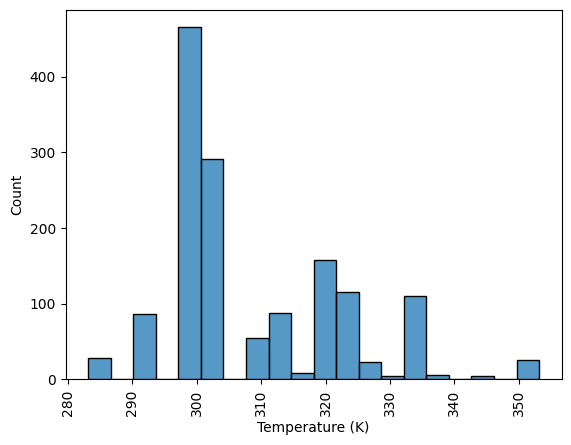

In [44]:
sns.histplot(data = phi_data, x = 'Temperature (K)')
plt.xticks(rotation = 90)
plt.show()

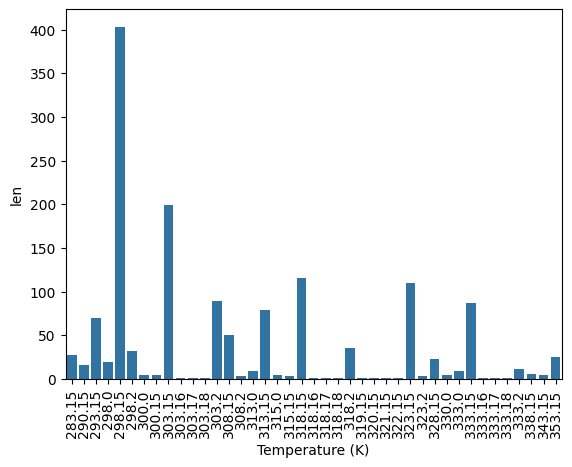

In [45]:
sns.barplot(data = temperature_tie_lines, x = 'Temperature (K)', y = 'len')
plt.xticks(rotation = 90)
plt.show()

In [46]:
tie_lines_per_alcohol = phi_data.group_by('Type Alcohol').len().sort(by='Type Alcohol')
tie_lines_per_alcohol

Type Alcohol,len
i64,u32
0,46
1,431
2,967
3,6
4,18


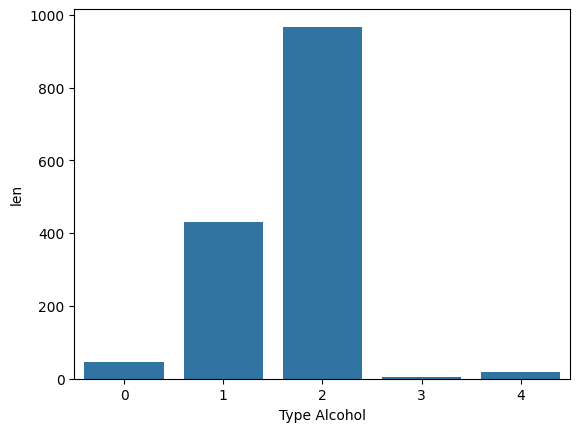

In [47]:
sns.barplot(data = tie_lines_per_alcohol, x = 'Type Alcohol', y = 'len')
plt.show()

In [48]:
columns_to_select = ['phi_FAME/FAEE', 'phi_GLYCEROL', 'phi_ALCOHOL', 'phi_OIL', 'phi_DAG', 'phi_MAG', 'phi_ACID','phi_WATER']

In [49]:
def mean_excluding_zeros(row):
    non_zero_values = [val for val in row if val != 0]
    if not non_zero_values:
        return None  # or return float('nan') if you prefer NaN
    return sum(non_zero_values) / len(non_zero_values)

In [50]:
experimental_phi = phi_data.with_columns(
    pl.concat_list(columns_to_select).map_elements(mean_excluding_zeros, return_dtype= float).alias('Experimental mean phi')
)


In [51]:
def absolute_errors(row, mean):
    return [abs(val - mean) if val != 0 else None for val in row]

In [52]:
df = experimental_phi.with_columns(
    pl.concat_list(columns_to_select).map_elements(
        lambda row: absolute_errors(row, mean_excluding_zeros(row)),
    return_dtype=list[float]).alias('abs_errors')
)


In [53]:
def mean_non_null(values):
    non_null_values = [val for val in values if val is not None]
    if not non_null_values:
        return None  # or return float('nan') if you prefer NaN
    return sum(non_null_values) / len(non_null_values)

# Calculate average absolute error for each row
df = df.with_columns(
    df['abs_errors'].map_elements(mean_non_null, return_dtype=float).alias('average_absolute_error')
)

In [62]:
filtered_phi_df = df.filter((pl.col('Experimental mean phi') <=1) & (pl.col('Experimental mean phi') > 0))
filtered_phi_df.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1413.0,1413.0,"""1413""",1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0,1413.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",729.631281,32.605803,null,308.586575,1.661005,0.178883,0.132316,0.360182,0.244741,0.001081,0.001152,0.023134,0.058165,0.402853,0.005801,0.135134,0.420655,0.001323,0.000706,0.024207,0.009415,0.012461,0.229169,0.579437,0.045871,0.000865,0.001563,0.022217,0.108352,0.210027,0.168215,0.444856,0.283201,0.022613,0.020842,0.200244,0.231378,0.476626,null,0.044519
"""std""",426.204069,14.980285,null,13.842751,0.590662,0.208694,0.182492,0.157658,0.22821,0.005528,0.006674,0.045575,0.118561,0.440484,0.013434,0.136128,0.408525,0.006768,0.00448,0.048987,0.032648,0.038159,0.310115,0.289097,0.111877,0.004401,0.008948,0.043114,0.216524,0.237506,0.228083,0.187893,0.262852,0.120434,0.098468,0.320021,0.267577,0.127825,null,0.083489
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.507519,0.0,-0.8125,-0.333333,-1.0,0.0,0.063604,null,0.0
"""25%""",357.0,22.0,null,298.15,1.0,0.0,0.0,0.25,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.0578,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.332,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.379121,0.0,0.0,0.0,0.0,0.0,0.415288,null,0.005415
"""50%""",726.0,35.0,null,303.15,2.0,0.0,0.0,0.4321,0.348,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.1005,0.5786,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.6543,0.003,0.0,0.0,0.0,0.0,0.0,0.0,0.493178,0.461234,0.0,0.0,0.0,0.0,0.492668,null,0.014766
"""75%""",1093.0,45.0,null,318.15,2.0,0.3626,0.3,0.4749,0.4721,0.0,0.0,0.0245,0.061,0.8955,0.0054,0.171,0.84,1.0000e-20,1.0000e-20,0.0253,0.0064,0.0121,0.4991,0.8355,0.0449,0.0,0.0,0.0245,0.114,0.425669,0.37537,0.528979,0.525406,0.0,0.0,0.468354,0.525406,0.538778,null,0.043806
"""max""",1467.0,57.0,"""da""",353.15,4.0,0.8459,0.7764,0.7689,0.6355,0.0586,0.0721,0.2506,0.5564,1.0,0.1471,0.9409,0.976,0.068,0.0572,0.2992,0.4084,0.4581,1.0,0.9949,0.894,0.0485,0.0929,0.2404,0.9999,0.877677,0.874608,2.229878,0.778746,0.888889,0.590909,2.0,0.949069,0.927951,null,0.912044


<Axes: ylabel='Count'>

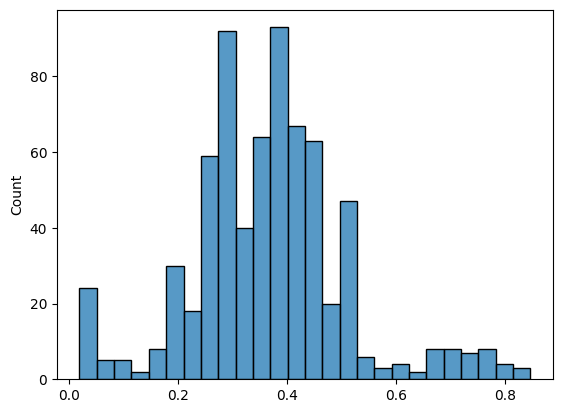

In [76]:
test = filtered_phi_df.filter(pl.col('FAME/FAEE_F') > 0.0)
sns.histplot(x = test.select(pl.col('FAME/FAEE_F')).to_numpy().reshape(690))

<Axes: ylabel='Count'>

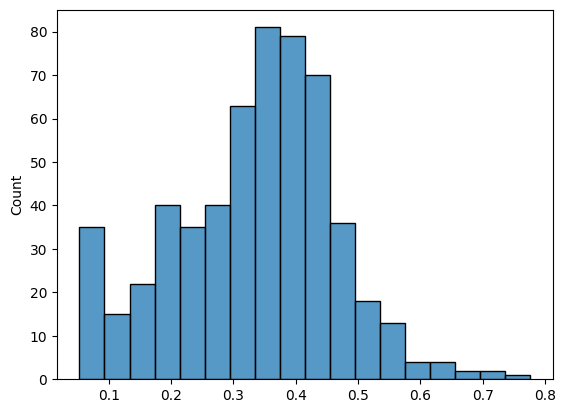

In [78]:
test = filtered_phi_df.filter(pl.col('GLYCEROL_F') > 0.0)
sns.histplot(x = test.select(pl.col('GLYCEROL_F')).to_numpy().reshape(560))

<Axes: ylabel='Count'>

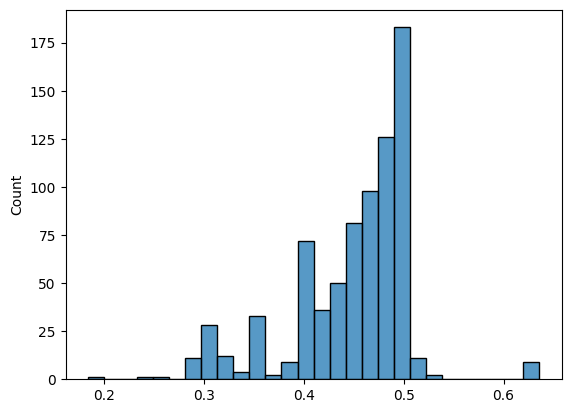

In [80]:
test = filtered_phi_df.filter(pl.col('OIL_F') > 0.0)
sns.histplot(x = test.select(pl.col('OIL_F')).to_numpy().reshape(770))

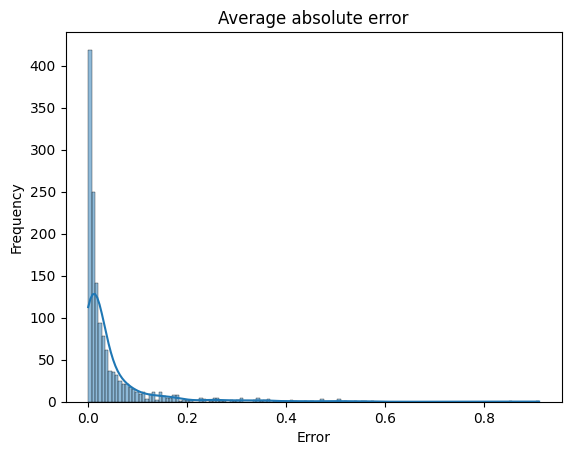

In [82]:

sns.histplot(x = filtered_phi_df.select(pl.col('average_absolute_error')).to_numpy().reshape(1413), kde = True).set(title = f'Average absolute error',  ylabel = 'Frequency', xlabel = 'Error')
plt.show()

Analizar los phi experimentales por componente antes y despues de la validación y reconciliación.

### 3.Analysis of refined data

In [2]:
thresholds = [0.05, 0.1, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.5, 0.55, 0.65, 0.70, 0.75]
lengths = []
for i in thresholds:
    validated_data = ExperimentalValidation(path_to_data=r'D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\OLEOSIM_Thermodynamics\Unifac_Dortmund\Experimental_Data\data\raw_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=0.20)._calculate_experimental_phi()
    lengths.append(validated_data.shape[0])
    
    

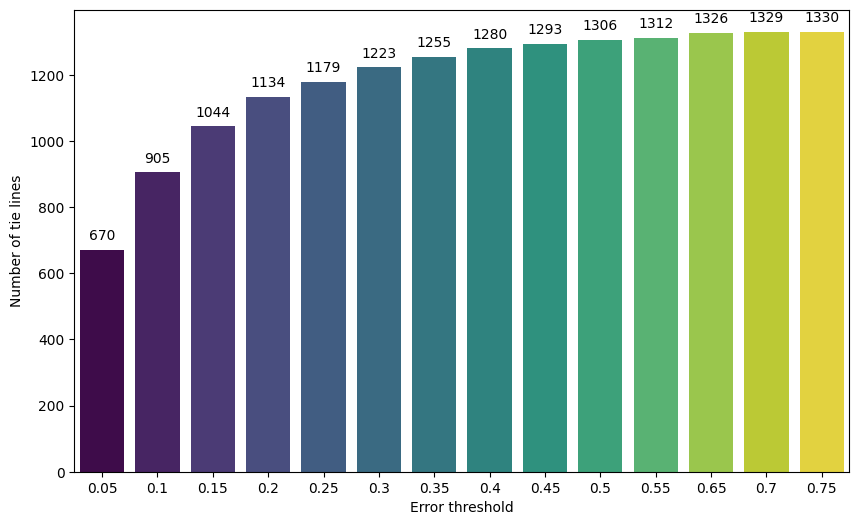

In [3]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=thresholds, y=lengths, palette='viridis', hue=thresholds, legend=False)

# Annotate the bars with the values
for p in ax.patches:
    ax.annotate(f'{p.get_height():.0f}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 10), 
                textcoords='offset points')

# Set labels and title
ax.set_xlabel('Error threshold')
ax.set_ylabel('Number of tie lines')

# Show the plot
plt.show()

In [23]:
raw_data = (pl.read_excel(r'D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\OLEOSIM_Thermodynamics\Unifac_Dortmund\Experimental_Data\data\raw_lle_data.xlsx', engine='calamine'))
